In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure display options
sns.set_theme(style="whitegrid")
df = pd.read_csv('Dataset .csv')

print(f"Dataset loaded successfully with {df.shape[0]} rows and {df.shape[1]} columns.")
df.head(3)

Dataset loaded successfully with 9551 rows and 21 columns.


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270


In [2]:
# Task 1: Determine the top three most common cuisines and their percentages
cuisines_split = df['Cuisines'].dropna().apply(lambda x: [c.strip() for c in x.split(',')])
all_cuisines = pd.Series([c for sublist in cuisines_split for c in sublist])

top_3_cuisines = all_cuisines.value_counts().head(3)
top_3_pct = (top_3_cuisines / len(df)) * 100

task1_df = pd.DataFrame({
    'Total Count': top_3_cuisines,
    'Percentage of Total Restaurants (%)': top_3_pct.round(2)
})
print("Top 3 Most Common Cuisines:")
print(task1_df)

Top 3 Most Common Cuisines:
              Total Count  Percentage of Total Restaurants (%)
North Indian         3960                                41.46
Chinese              2735                                28.64
Fast Food            1986                                20.79


In [3]:
# Task 2: City with highest restaurant volume & city with highest average rating
city_counts = df['City'].value_counts()
top_city = city_counts.idxmax()
print(f"1. City with the highest number of restaurants: {top_city} ({city_counts.max()} restaurants)")

city_ratings = df.groupby('City')['Aggregate rating'].mean()
top_rated_city = city_ratings.idxmax()
print(f"2. City with the highest average rating: {top_rated_city} ({city_ratings.max():.2f}/5.0)")

print("\nTop 5 Cities by Average Rating:")
print(city_ratings.sort_values(ascending=False).head(5).round(2))

1. City with the highest number of restaurants: New Delhi (5473 restaurants)
2. City with the highest average rating: Inner City (4.90/5.0)

Top 5 Cities by Average Rating:
City
Inner City          4.90
Quezon City         4.80
Makati City         4.65
Pasig City          4.63
Mandaluyong City    4.62
Name: Aggregate rating, dtype: float64


             Count  Percentage (%)
Price range                       
1             4444           46.53
2             3113           32.59
3             1408           14.74
4              586            6.14


C:\Users\JERROME M JACOB\AppData\Local\Temp\ipykernel_16208\7609421.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=price_counts.index, y=price_counts.values, palette='Blues_d')


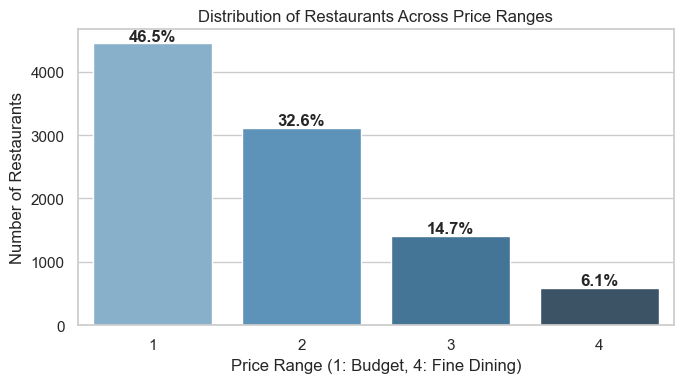

In [4]:
# Task 3: Visualize price range distribution & calculate percentage per category
price_counts = df['Price range'].value_counts().sort_index()
price_pct = (price_counts / len(df)) * 100

price_df = pd.DataFrame({
    'Count': price_counts,
    'Percentage (%)': price_pct.round(2)
})
print(price_df)

# Plotting the distribution
plt.figure(figsize=(7, 4))
ax = sns.barplot(x=price_counts.index, y=price_counts.values, palette='Blues_d')
plt.title('Distribution of Restaurants Across Price Ranges')
plt.xlabel('Price Range (1: Budget, 4: Fine Dining)')
plt.ylabel('Number of Restaurants')

for i, count in enumerate(price_counts.values):
    ax.text(i, count + 40, f"{price_pct.iloc[i]:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [5]:
# Task 4: Online delivery share & rating comparison
delivery_pct = df['Has Online delivery'].value_counts(normalize=True) * 100
avg_ratings = df.groupby('Has Online delivery')['Aggregate rating'].mean()

print("Percentage of restaurants offering online delivery:")
print(delivery_pct.round(2))

print("\nAverage rating comparison (Online Delivery vs No Delivery):")
print(avg_ratings.round(2))

Percentage of restaurants offering online delivery:
Has Online delivery
No     74.34
Yes    25.66
Name: proportion, dtype: float64

Average rating comparison (Online Delivery vs No Delivery):
Has Online delivery
No     2.47
Yes    3.25
Name: Aggregate rating, dtype: float64
